In [1]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [8]:
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import accuracy_score, f1_score

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

from sklearn.tree import DecisionTreeClassifier                                  # single model
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier  # 2 ensembles
from sklearn.linear_model import LogisticRegression                              # other 1
from sklearn.svm import SVC                                                      # other 2

# 1.Load Dataset

In [10]:
import pandas as pd

# CSV file path (VS Code folder path)
finance = pd.read_csv("Finance_data.csv")
original = pd.read_csv("Original_data.csv")

# basic review
print(finance.shape)      # (40, 24)
print(finance.head())
finance.info()

(40, 24)
   gender  age Investment_Avenues  Mutual_Funds  Equity_Market  Debentures  \
0  Female   34                Yes             1              2           5   
1  Female   23                Yes             4              3           2   
2    Male   30                Yes             3              6           4   
3    Male   22                Yes             2              1           3   
4  Female   24                 No             2              1           3   

   Government_Bonds  Fixed_Deposits  PPF  Gold  ...           Duration  \
0                 3               7    6     4  ...          1-3 years   
1                 1               5    6     7  ...  More than 5 years   
2                 2               5    1     7  ...          3-5 years   
3                 7               6    4     5  ...   Less than 1 year   
4                 6               4    5     7  ...   Less than 1 year   

  Invest_Monitor   Expect       Avenue What are your savings objectives?  \
0

## Variable Groups

| Group | Columns | Description |
|---|---|---|
| Demographics | `gender`, `age` | Gender and age |
| Investment participation | `Investment_Avenues`, `Stock_Marktet` | Invests in investment avenues (Yes 37 / No 3); invests in stock market (Yes 35 / No 5) |
| Avenue preference ranking | `Mutual_Funds`, `Equity_Market`, `Debentures`, `Government_Bonds`, `Fixed_Deposits`, `PPF`, `Gold` | Preference rank (1-7) for 7 investment options (1 = most preferred) |
| Investment attitudes | `Factor`, `Objective`, `Purpose`, `Duration`, `Invest_Monitor`, `Expect` | Key decision factor, objective, purpose, holding period, monitoring frequency, expected return |
| Main investment avenue | `Avenue` | Avenue the respondent mostly invests in (modeling target) |
| Savings and investment reasons | `What are your savings objectives?`, `Reason_Equity`, `Reason_Mutual`, `Reason_Bonds`, `Reason_FD` | Savings objective and reasons for investing in each product |

## Key Caveats

- **Small, biased sample.** Only 40 respondents, concentrated in their 20s to early 30s, so results cannot be generalized to investors overall.
- **Heavy class imbalance.** `Stock_Marktet` (35:5), `Purpose` (Wealth Creation 32/40), and `Expect` (20%-30% 32/40) are dominated by one value and discriminate poorly. Some classes are very small, such as PPF in `Avenue` (3 records).

# Dataset Column Description

## 1. Demographics (2 Columns)

| Column Name | Meaning | Data Type | Example Values |
|---|---|---|---|
| `gender` | Respondent's gender | Categorical | Male, Female |
| `age` | Respondent's age | Numerical | 21, 27, 34 |

## 2. Investment Participation (2 Columns)

| Column Name | Meaning | Data Type | Example Values |
|---|---|---|---|
| `Investment_Avenues` | Whether the respondent invests in investment avenues | Categorical (Yes/No) | Yes, No |
| `Stock_Marktet` | Whether the respondent invests in the stock market | Categorical (Yes/No) | Yes, No |

## 3. Avenue Preference Ranking (7 Columns)

These columns represent the respondent's preference ranking for seven investment options.

**Ranking Scale:** 1 = Most Preferred, 7 = Least Preferred.

| Column Name | Meaning | Data Type | Example Values |
|---|---|---|---|
| `Mutual_Funds` | Preference ranking for mutual funds | Ordinal | 1–7 |
| `Equity_Market` | Preference ranking for equity market investments | Ordinal | 1–7 |
| `Debentures` | Preference ranking for debentures | Ordinal | 1–7 |
| `Government_Bonds` | Preference ranking for government bonds | Ordinal | 1–7 |
| `Fixed_Deposits` | Preference ranking for fixed deposits | Ordinal | 1–7 |
| `PPF` | Preference ranking for Public Provident Fund | Ordinal | 1–7 |
| `Gold` | Preference ranking for gold investments | Ordinal | 1–7 |

## 4. Investment Attitudes (6 Columns)

| Column Name | Meaning | Data Type | Example Values |
|---|---|---|---|
| `Factor` | Main factor influencing investment decisions | Categorical | Returns, Risk, Locking Period |
| `Objective` | Main investment objective | Categorical | Capital Appreciation, Income, Growth |
| `Purpose` | Main purpose of investment | Categorical | Wealth Creation, Savings for Future, Returns |
| `Duration` | Expected investment holding period | Ordinal / Categorical | Less than 1 year, 1-3 years, 3-5 years, More than 5 years |
| `Invest_Monitor` | Frequency of monitoring investments | Ordinal / Categorical | Daily, Weekly, Monthly |
| `Expect` | Expected return on investment | Ordinal / Categorical | 10%-20%, 20%-30%, 30%-40% |

## 5. Main Investment Avenue (1 Column)

| Column Name | Meaning | Data Type | Example Values |
|---|---|---|---|
| `Avenue` | Main investment product in which the respondent mostly invests. This is the target variable for machine learning prediction. | Categorical | Mutual Fund, Equity, Fixed Deposits, Public Provident Fund |

## 6. Savings and Investment Reasons (5 Columns)

| Column Name | Meaning | Data Type | Example Values |
|---|---|---|---|
| `What are your savings objectives?` | Main objective of the respondent's savings | Categorical | Retirement Plan, Health Care, Education |
| `Reason_Equity` | Main reason for investing in equity | Categorical | Capital Appreciation, Dividend, Liquidity |
| `Reason_Mutual` | Main reason for investing in mutual funds | Categorical | Better Returns, Tax Benefits, Fund Diversification |
| `Reason_Bonds` | Main reason for investing in bonds | Categorical | Safe Investment, Assured Returns, Tax Incentives |
| `Reason_FD` | Main reason for investing in fixed deposits | Categorical | Fixed Returns, High Interest Rates, Risk Free |

## 7. Additional Information (1 Column)

| Column Name | Meaning | Data Type | Example Values |
|---|---|---|---|
| `Source` | Source of information from which the respondent learns about investment options | Categorical | Newspapers and Magazines, Financial Consultants, Television, Internet |

---

## Dataset Summary

| Variable Group | Number of Columns |
|---|---:|
| Demographics | 2 |
| Investment Participation | 2 |
| Avenue Preference Ranking | 7 |
| Investment Attitudes | 6 |
| Main Investment Avenue | 1 |
| Savings and Investment Reasons | 5 |
| Additional Information | 1 |
| **Total** | **24** |

### Important Notes

- `Avenue` is the target variable used to predict the respondent's main investment choice.
- The remaining 23 columns represent respondent characteristics, investment preferences, attitudes, and other information.
- The seven investment preference columns use a ranking scale from 1 (most preferred) to 7 (least preferred).
- `age` is numerical, while most other columns contain categorical or ordinal data.
- `Stock_Marktet` is the original column name in the dataset and retains its original spelling.

# 2. 5 models

Data shape: (40, 24)
Target distribution:
 Avenue
Mutual Fund              18
Equity                   10
Fixed Deposits            9
Public Provident Fund     3
Name: count, dtype: int64 

                       Model  Accuracy mean  Accuracy std  F1 (macro) mean
Gradient Boosting (ensemble)          0.408         0.124            0.295
    Random Forest (ensemble)          0.405         0.111            0.221
      Decision Tree (single)          0.312         0.106            0.213
         Logistic Regression          0.325         0.099            0.203
                   SVM (RBF)          0.448         0.019            0.156

Baseline (always predict the majority class): 0.450


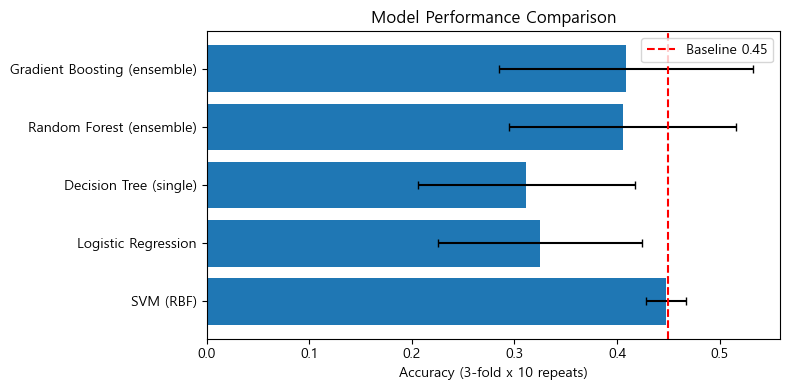


===== Top model: Gradient Boosting (ensemble) =====
                       precision    recall  f1-score   support

               Equity       0.38      0.30      0.33        10
       Fixed Deposits       0.15      0.22      0.18         9
          Mutual Fund       0.44      0.44      0.44        18
Public Provident Fund       0.00      0.00      0.00         3

             accuracy                           0.33        40
            macro avg       0.24      0.24      0.24        40
         weighted avg       0.33      0.33      0.32        40



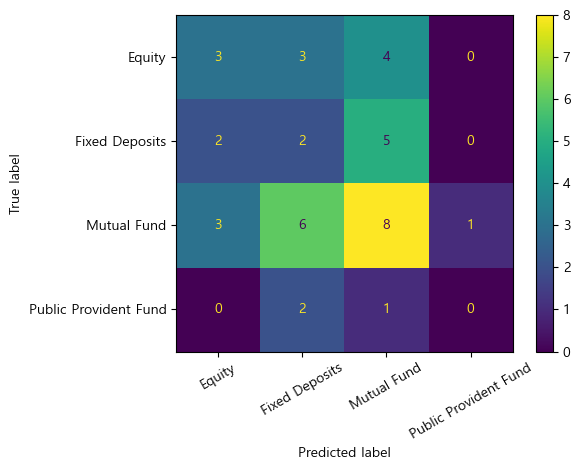

In [13]:
# ------------------------------------------------------------------
# 1. Load data and clean column names
# ------------------------------------------------------------------
df = pd.read_csv("Finance_data.csv")
df = df.rename(columns={
    "Stock_Marktet": "Stock_Market",
    "What are your savings objectives?": "Savings_Objective",
})

TARGET = "Avenue"          # main investment avenue (4 classes)
X = df.drop(columns=[TARGET])
y = df[TARGET]

print("Data shape:", df.shape)
print("Target distribution:\n", y.value_counts(), "\n")

# ------------------------------------------------------------------
# 2. Preprocessing (scale numeric, one-hot encode categorical)
# ------------------------------------------------------------------
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

# ------------------------------------------------------------------
# 3. Define the 5 models
# ------------------------------------------------------------------
models = {
    "Decision Tree (single)":      DecisionTreeClassifier(max_depth=4, random_state=42),
    "Random Forest (ensemble)":    RandomForestClassifier(n_estimators=300, random_state=42),
    "Gradient Boosting (ensemble)": GradientBoostingClassifier(random_state=42),
    "Logistic Regression":         LogisticRegression(max_iter=2000),
    "SVM (RBF)":                   SVC(kernel="rbf", C=1.0),
}

pipes = {name: Pipeline([("prep", preprocess), ("model", m)]) for name, m in models.items()}

# ------------------------------------------------------------------
# 4. Compare with cross-validation (a single train/test split is
#    unstable with only 40 rows). The PPF class has only 3 samples,
#    so use 3-fold repeated 10 times.
# ------------------------------------------------------------------
cv = RepeatedStratifiedKFold(n_splits=3, n_repeats=10, random_state=42)
scoring = ["accuracy", "f1_macro"]

rows = []
for name, pipe in pipes.items():
    r = cross_validate(pipe, X, y, cv=cv, scoring=scoring)
    rows.append({
        "Model": name,
        "Accuracy mean": r["test_accuracy"].mean(),
        "Accuracy std": r["test_accuracy"].std(),
        "F1 (macro) mean": r["test_f1_macro"].mean(),
    })

result = pd.DataFrame(rows).sort_values("F1 (macro) mean", ascending=False).reset_index(drop=True)
baseline = y.value_counts(normalize=True).max()

print(result.round(3).to_string(index=False))
print(f"\nBaseline (always predict the majority class): {baseline:.3f}")

# ------------------------------------------------------------------
# 5. Visualization
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(result["Model"][::-1], result["Accuracy mean"][::-1],
        xerr=result["Accuracy std"][::-1], capsize=3)
ax.axvline(baseline, color="red", linestyle="--", label=f"Baseline {baseline:.2f}")
ax.set_xlabel("Accuracy (3-fold x 10 repeats)")
ax.set_title("Model Performance Comparison")
ax.legend()
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()

# ------------------------------------------------------------------
# 6. Detailed evaluation of the top model
# ------------------------------------------------------------------
best_name = result.loc[0, "Model"]
best_pipe = pipes[best_name]
pred = cross_val_predict(best_pipe, X, y, cv=RepeatedStratifiedKFold(n_splits=3, n_repeats=1, random_state=0))

print(f"\n===== Top model: {best_name} =====")
print(classification_report(y, pred, zero_division=0))

ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=sorted(y.unique())),
                       display_labels=sorted(y.unique())).plot(xticks_rotation=30)
plt.tight_layout()
plt.show()

# Model Comparison Summary

**Goal:** Predict primary investment avenue (`Avenue`, 4 classes) from 40 survey responses using 5 models. Evaluation: 3-fold CV x 10 repeats.

**Repeated 3-fold cross-validation with 10 different random splits**

| Model | Accuracy | F1 (macro) |
|---|---|---|
| Gradient Boosting | 0.408 | 0.295 |
| Random Forest | 0.405 | 0.221 |
| Decision Tree | 0.312 | 0.213 |
| Logistic Regression | 0.325 | 0.203 |
| SVM | 0.448 | 0.156 |
| Baseline (majority class) | 0.450 | - |

**SVM** – Predicts the main investment product (Avenue) based on investors' characteristics.

**Key findings**
- **Gradient Boosting** is the best model by **F1 (macro)**; accuracy was avoided because of class imbalance.
- **SVM**'s **high accuracy** is misleading: it predicts almost only the majority class.
- Ensembles outperformed the single Decision Tree.
- No model beat the baseline accuracy, so **prediction is not yet reliable**.

**Next steps:** more data, feature selection, or a binary task (Mutual Fund vs. others).

## Future Improvements for Model Performance

The following approaches can be considered to improve the performance and reliability of the machine learning models.

| Improvement Method | Description |
|---|---|
| **Data Collection** | Collect more training samples, especially for underrepresented classes such as Public Provident Fund, to improve classification performance. |
| **Class Weight Adjustment** | Assign higher weights to minority classes so that the model pays more attention to categories with fewer observations. |
| **SMOTE (Synthetic Minority Over-sampling Technique)** | Generate synthetic samples for minority classes to address class imbalance in the training dataset. |
| **Hyperparameter Tuning** | Optimize the model's parameters to improve predictive performance and reduce classification errors. |
| **Feature Engineering** | Create, select, or transform relevant features to improve the model's ability to distinguish between different investment product categories. |
| **Cross-Validation Improvement** | Evaluate model performance using multiple data splits to obtain more reliable and consistent performance estimates. |

### Conclusion

Future improvements should focus on addressing class imbalance, increasing the amount of training data, and optimizing model parameters. These approaches may help improve classification accuracy and achieve more balanced predictions across all investment product categories.